# 02. 실제 세포 하나: 경로 부분과 나머지 부분

이 노트북은 서버의 입력 캐시가 있어야 실행됩니다(`experiments/softprior_multitask_r1/r0_build.sbatch`가 만든 것). 연구 전체를 다시 학습하지 않고, 한 학습 집합에서 닫힌 해로 풀리는 작은 Ridge 몇 개만 계산합니다(수 초). RNA 값은 출력하지 않습니다(예시 약물 하나의 관측 AA와 예측만 나란히 보여 줍니다).

In [1]:
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "configs", "softprior_multitask_r1")):
    parent = os.path.dirname(root)
    assert parent != root, "저장소 안에서 실행해 주세요."
    root = parent
sys.path.insert(0, os.path.join(root, "src", "softprior_multitask_r1"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
T = os.path.join(root, "reports", "softprior_multitask_r1", "tables")
print("결과표 폴더를 찾았습니다:", os.path.isdir(T))
import r1_data as R, r1_models as M
cfg = R.load_config(); data = R.load_data(cfg)
print("모델", len(data.models), "계열", len(set(data.fam)), "유전자", data.rank.shape[1], "약물", len(data.drugs), "경로", len(data.sets))

결과표 폴더를 찾았습니다: True


모델 79 계열 76 유전자 19018 약물 90 경로 50


## 1. 유전자 19,018개의 방향 가운데 '경로 방향'은 몇 개인가

Hallmark 경로 50개의 평균 점수로 만들 수 있는 예측은, 유전자 공간에서 보면 최대 50개의 방향만 사용합니다. soft prior는 이 50개 방향은 보통 강도로, 나머지 방향은 더 세게 규제합니다. 나머지를 **버리지는 않습니다.**

In [2]:
fold = data.outer_fold(0)
tr, te = fold != 0, fold == 0
prep = M.Prep(data.rank[tr], data.Y[tr], data.fam[tr], data.rank[te], data.sets)
print("학습 모델", int(tr.sum()), "/ 보류 모델", int(te.sum()))
print("경로 부분공간의 차원:", prep.r)
print("표준화한 학습 RNA 분산 가운데 경로 부분공간에 있는 몫: %.1f%%" % (100 * prep.par_fraction))

학습 모델 63 / 보류 모델 16
경로 부분공간의 차원: 50
표준화한 학습 RNA 분산 가운데 경로 부분공간에 있는 몫: 1.6%


## 2. 보류된 세포 하나를 두 부분으로 나누기

세포의 표준화된 RNA 벡터 x를 x = (경로 부분) + (나머지 부분)으로 나눕니다. 두 부분은 직교합니다.

In [3]:
import r1_solvers as S
Q = S.orth_basis(S.membership_std(data.sets, prep.x_sd))
i = np.where(te)[0][0]
x = S.standardise(data.rank[[i]], prep.x_mu, prep.x_sd)[0]
x_par = Q @ (Q.T @ x); x_rest = x - x_par
print("세포:", data.models[i])
print("전체 크기² %.0f = 경로 부분 %.0f + 나머지 %.0f" % (x @ x, x_par @ x_par, x_rest @ x_rest))
print("경로 부분의 몫: %.1f%%, 두 부분의 내적: %.1e" % (100 * (x_par @ x_par) / (x @ x), x_par @ x_rest))

세포: LIMORE__CLC1
전체 크기² 17248 = 경로 부분 293 + 나머지 16954
경로 부분의 몫: 1.7%, 두 부분의 내적: -8.9e-15


경로 부분은 이 세포 RNA 변이의 일부만 담습니다. hard prior(경로 점수만 입력)는 나머지를 전부 버리는 선택입니다.

## 3. 같은 약물에서 hard / soft / prior 없음의 예측

같은 학습 집합, 같은 규제 강도(λ=1)에서 세 가지를 풀어 보류 세포의 예측을 비교합니다. η/λ = ∞가 hard, 10이 soft, 0이 prior 없는 Ridge입니다.

In [4]:
drug = "Sorafenib"; d = data.drugs.index(drug)
out = pd.DataFrame({"observed_AA": data.Y[te][:, d]}, index=[m.replace("LIMORE__", "") for m, t in zip(data.models, te) if t])
for name, kernel in [("hard", "par"), ("soft_eta10", "r10"), ("no_prior", "whole")]:
    out[name] = prep.to_raw(prep.predict_ridge_z(kernel, 1.0))[:, d]
out["train_mean"] = prep.y_mu[d]
print(out.round(3).to_string())
print("\n예측끼리의 상관:"); print(out[["hard", "soft_eta10", "no_prior"]].corr().round(3))
print("\n이 fold·이 약물의 RMSE:"); print(((out.drop(columns="observed_AA").sub(out.observed_AA, axis=0)) ** 2).mean().pow(0.5).round(4))

        observed_AA   hard  soft_eta10  no_prior  train_mean
CLC1          0.126  0.103       0.106     0.108       0.103
CLC10         0.075  0.098       0.091     0.085       0.103
CLC25         0.094  0.096       0.094     0.090       0.103
CLC27         0.068  0.100       0.094     0.091       0.103
CLC34         0.032  0.102       0.105     0.106       0.103
CLC37         0.129  0.103       0.109     0.113       0.103
CLC38         0.075  0.112       0.129     0.141       0.103
CLC44         0.061  0.109       0.114     0.113       0.103
CLC46         0.161  0.107       0.121     0.139       0.103
CLC5          0.068  0.100       0.101     0.100       0.103
CLC8          0.060  0.093       0.089     0.088       0.103
JHH6          0.086  0.094       0.085     0.077       0.103
JHH7          0.174  0.108       0.121     0.141       0.103
SNU354        0.247  0.099       0.096     0.099       0.103
SNU739        0.056  0.101       0.102     0.104       0.103
Tong          0.092  0.1

한 fold, 한 약물의 숫자는 우연에 크게 흔들립니다. 결론은 01 노트북의 전체 표(계열 76개, 약물 90개, 반복 3회)에서만 읽어야 합니다.

## 4. 유전자를 많이 넣어서 좋아진 것인가, 규제가 기여한 것인가

같은 학습 집합의 안쪽 fold에서, 규제 강도 λ를 바꿔 가며 세 입력의 손실을 봅니다. '전체'는 λ가 작으면 나빠지고 적당한 λ에서 가장 좋습니다. 유전자를 더 넣는 것만으로는 좋아지지 않고, 맞는 규제가 함께 있어야 합니다. '경로 뺀 나머지'가 '전체'와 거의 같다는 점도 보입니다.

           0.0001    0.0010    0.0100    0.1000    1.0000    10.0000   100.0000
전체           1.0410    1.0410    1.0409    1.0402    1.0366    1.0468    1.0808
경로만(hard)    2.0025    1.5874    1.2952    1.1275    1.0717    1.0879    1.0931
경로 뺀 나머지     1.0390    1.0390    1.0390    1.0383    1.0351    1.0469    1.0813


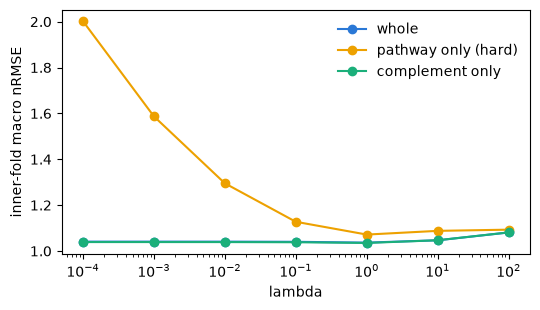

In [5]:
lams = cfg["objective"]["lambda_grid"]
cfgs = M.ridge_configs(lams, ["whole", "par", "perp"])
loss, _ = M.inner_losses(data.rank[tr], data.Y[tr], data.fam[tr], data.sets, cfgs, 3, R.inner_seed(cfg, 0, 0))
tab = pd.DataFrame(np.sqrt(loss).mean(axis=1).reshape(3, len(lams)), index=["전체", "경로만(hard)", "경로 뺀 나머지"], columns=lams)
print(tab.round(4).to_string())
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for (name, row), c in zip(tab.iterrows(), ["#2a78d6", "#eda100", "#1baf7a"]):
    ax.plot(lams, row.values, "o-", color=c, label=["whole", "pathway only (hard)", "complement only"][list(tab.index).index(name)])
ax.set_xscale("log"); ax.set_xlabel("lambda"); ax.set_ylabel("inner-fold macro nRMSE"); ax.legend(frameon=False); plt.tight_layout(); plt.show()